## 1 importing the libraries

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 2 importing the file

In [30]:
path = r"C:\pp\ml--2026\2w\chipotle.tsv"
chipo = pd.read_csv(path, sep = "\t")

## 3 loading the first 5 rows

In [31]:
chipo.head()

,order_id,quantity,item_name,choice_description,item_price
0,1,1,Chips and Fresh Tomato Salsa,NaN,$2.39
1,1,1,Izze,[Clementine],$3.39
2,1,1,Nantucket Nectar,[Apple],$3.39
3,1,1,Chips and Tomatillo-Green Chili Salsa,NaN,$2.39
4,2,2,Chicken Bowl,"[Tomatillo-Red Chili Salsa (Hot), [Black Beans...",$16.98


## 4 how many rows and columns the dataset have?

In [33]:
chipo.shape

(4622, 5)

## 5 column names in the dataset

In [35]:
chipo.columns

Index(['order_id', 'quantity', 'item_name', 'choice_description',
       'item_price'],
      dtype='object')

## 6 how is the dataset indexed

In [36]:
chipo.index

RangeIndex(start=0, stop=4622, step=1)

## 7 which columns are categorical and which are numerical?

In [38]:
ct = chipo.select_dtypes(include = "object").columns
nm = chipo.select_dtypes(exclude = "object").columns

print(ct)
print(nm)

Index(['item_name', 'choice_description', 'item_price'], dtype='object')
Index(['order_id', 'quantity'], dtype='object')


## 8 why is item_price is considered as categorical?

In [49]:
chipo.dtypes

order_id                int64
quantity                int64
item_name              object
choice_description     object
item_price            float64
dtype: object

## 9 convert item to a numerical col

In [47]:
chipo["item_price"] = chipo["item_price"].str.replace('$', '').astype(float)

## 9' checking item_price's type

In [48]:
chipo["item_price"].dtype

dtype('float64')

## 10 show basic statistics

In [50]:
chipo.describe

<bound method NDFrame.describe of       order_id  quantity                              item_name  \
0            1         1           Chips and Fresh Tomato Salsa   
1            1         1                                   Izze   
2            1         1                       Nantucket Nectar   
3            1         1  Chips and Tomatillo-Green Chili Salsa   
4            2         2                           Chicken Bowl   
...        ...       ...                                    ...   
4617      1833         1                          Steak Burrito   
4618      1833         1                          Steak Burrito   
4619      1834         1                     Chicken Salad Bowl   
4620      1834         1                     Chicken Salad Bowl   
4621      1834         1                     Chicken Salad Bowl   

                                     choice_description  item_price  
0                                                   NaN        2.39  
1                    

## 11 how many products more than $10.00?

In [60]:
chipo[chipo.item_price>10.00]["order_id"].count()
chipo[chipo.item_price>10.00]["order_id"].size

#count - measures valis entries
#size - measures total entries


1130

## 12 what is the price of each item?

In [67]:
prices = chipo[["item_name", "item_price"]]
prices

,item_name,item_price
0,Chips and Fresh Tomato Salsa,2.39
1,Izze,3.39
2,Nantucket Nectar,3.39
3,Chips and Tomatillo-Green Chili Salsa,2.39
4,Chicken Bowl,16.98
...,...,...
4617,Steak Burrito,11.75
4618,Steak Burrito,11.75
4619,Chicken Salad Bowl,11.25
4620,Chicken Salad Bowl,8.75


## 13 sort the dataset by the item name

In [71]:
chipo.sort_values(by = "item_name")
chipo.item_name.sort_values()

3389    6 Pack Soft Drink
341     6 Pack Soft Drink
1849    6 Pack Soft Drink
1860    6 Pack Soft Drink
2713    6 Pack Soft Drink
              ...        
2384    Veggie Soft Tacos
781     Veggie Soft Tacos
2851    Veggie Soft Tacos
1699    Veggie Soft Tacos
1395    Veggie Soft Tacos
Name: item_name, Length: 4622, dtype: object

## 14 what is the wuantity of the most expensive item ordered?

In [80]:
chipo.sort_values(by = "item_price", ascending = False)["quantity"].head(1)

3598    15
Name: quantity, dtype: int64

In [82]:
chipo.sort_values(by = "item_price", ascending = False)["quantity"].head(1).values[0]

np.int64(15)

In [83]:
chipo.sort_values(by = "item_price", ascending = False)["quantity"].iloc[0]

np.int64(15)

In [85]:
chipo.sort_values(by = "item_price", ascending = False)["quantity"].head(1).item()

15

## 15 how many times was a veggie salad bowl ordered

In [86]:
print(chipo[chipo.item_name == "Veggie Salad Bowl"]["quantity"].sum())

18


## 16 how many times did someone order than 1 Canned Soda?

In [92]:
condition = (chipo.item_name == "Canned Soda") & (chipo.quantity > 1)
chipo[condition]["quantity"].count()

np.int64(20)

## 17 how many different products are sold

In [94]:
unique_products = chipo["item_name"].nunique()
print(unique_products)

50


## 18 what is total revenue?

In [101]:
total_revenue = (chipo["item_price"] * chipo["quantity"]).sum()
print(round(total_revenue))

39237


## 19 what is the avg price of items?

In [104]:
avg_price = chipo["item_price"].mean()
print(round(avg_price, 2))

7.46


## 20 how many orders were made in total?

In [105]:
total_orders = chipo["order_id"].nunique()
print(total_orders)

1834


## 21 what is the total quantity of items ordered?

In [106]:
total_quantity = chipo["quantity"].sum()
print(total_quantity)

4972


## 22 which item has the highest avg price?

In [108]:
chipo.groupby("item_name")["item_price"].mean().idxmax()

'Bowl'

## 23 how may items include chicken in their name?

In [112]:
chicken = chipo[chipo["item_name"].str.contains("Chicken")]["item_name"].count()
print(chicken)

1560


## 24 which item was the most-ordered item?

In [116]:
chipo.groupby("item_name")["quantity"].sum().idxmax()

'Chicken Bowl'

## 25 group the dataset by item and count how many times each product appears

In [118]:
chipo.groupby("item_name").size().sort_values(ascending = False)

item_name
Chicken Bowl                             726
Chicken Burrito                          553
Chips and Guacamole                      479
Steak Burrito                            368
Canned Soft Drink                        301
Steak Bowl                               211
Chips                                    211
Bottled Water                            162
Chicken Soft Tacos                       115
Chicken Salad Bowl                       110
Chips and Fresh Tomato Salsa             110
Canned Soda                              104
Side of Chips                            101
Veggie Burrito                            95
Barbacoa Burrito                          91
Veggie Bowl                               85
Carnitas Bowl                             68
Barbacoa Bowl                             66
Carnitas Burrito                          59
Steak Soft Tacos                          55
6 Pack Soft Drink                         54
Chips and Tomatillo Red Chili Salsa       48


## 26 calc the total quantity sold for each product

In [119]:
item_quantity = chipo.groupby("item_name")["quantity"].sum()
item_quantity

item_name
6 Pack Soft Drink                         55
Barbacoa Bowl                             66
Barbacoa Burrito                          91
Barbacoa Crispy Tacos                     12
Barbacoa Salad Bowl                       10
Barbacoa Soft Tacos                       25
Bottled Water                            211
Bowl                                       4
Burrito                                    6
Canned Soda                              126
Canned Soft Drink                        351
Carnitas Bowl                             71
Carnitas Burrito                          60
Carnitas Crispy Tacos                      8
Carnitas Salad                             1
Carnitas Salad Bowl                        6
Carnitas Soft Tacos                       40
Chicken Bowl                             761
Chicken Burrito                          591
Chicken Crispy Tacos                      50
Chicken Salad                              9
Chicken Salad Bowl                       123


## 27 qhat is the avg quantity of items per order?

In [120]:
avg_it_per_order = chipo.groupby("order_id")["quantity"].mean()
avg_it_per_order

order_id
1       1.0
2       2.0
3       1.0
4       1.0
5       1.0
       ... 
1830    1.0
1831    1.0
1832    1.0
1833    1.0
1834    1.0
Name: quantity, Length: 1834, dtype: float64

## 28 plot the top 5 the most ordered items

<Axes: xlabel='item_name'>

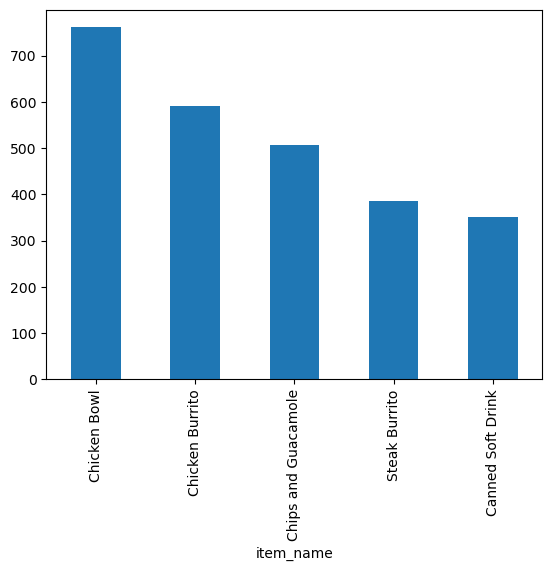

In [122]:
top5 = chipo.groupby("item_name")["quantity"].sum().sort_values(ascending = False).head(5)
top5.plot(kind = "bar")

## 29 plot the total quantity sold for the top 10 items

<Axes: xlabel='item_name'>

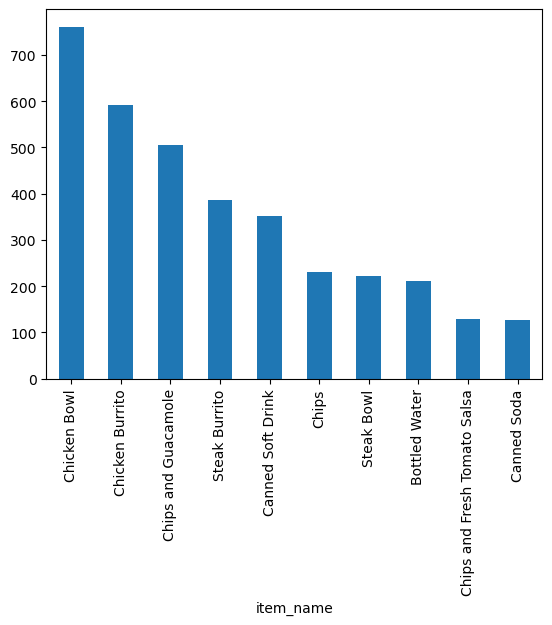

In [125]:
top10 = chipo.groupby("item_name")["quantity"].sum().sort_values(ascending = False).head(10)
top10.plot(kind = "bar")

## 30 calc thye total revenue generated by each item and plot the top 10 highest revenue items

<Axes: xlabel='item_name'>

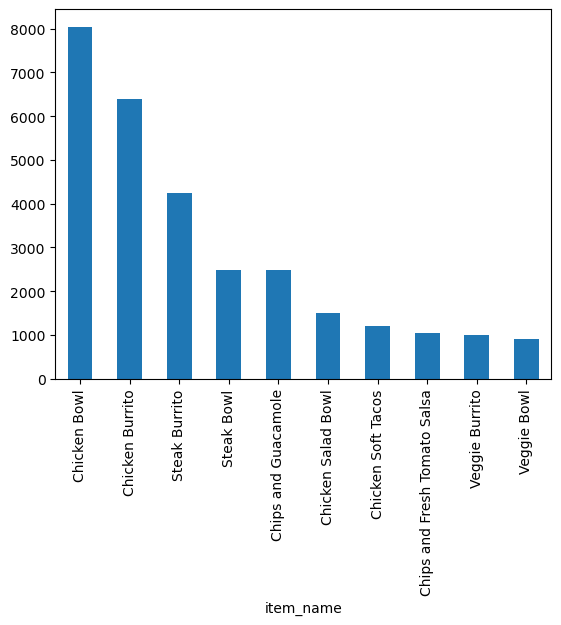

In [130]:
chipo["revenue"] = chipo["item_price"]*chipo["quantity"]
chipo.groupby("item_name")["revenue"].sum().sort_values(ascending = False).head(10).plot(kind = "bar")

revenue = (chipo["item_price"]*chipo["quantity"]).groupby(chipo["item_name"]).sum()

top10_revenue = revenue.sort_values(ascending = False).head(10)

top10_revenue.plot(kind = "bar")

## 31 which item was the most-ordered item?

In [171]:
chipo.groupby("item_name")["quantity"].sum().sort_values(ascending = False).head(1)

item_name
8.75    730
Name: quantity, dtype: int64

## 32 avg revenye amount per order?

In [172]:
chipo["revenue"] = chipo["item_price"]*chipo["quantity"]
rev_avg = chipo.groupby("order_id")["revenue"].sum()
rev_avg.mean()

np.float64(21.39423118865867)

## 33 which product has the highest total quantity sold?

In [173]:
chipo.groupby("item_name")["quantity"].sum().sort_values(ascending=False).head(1)                                      


item_name
8.75    730
Name: quantity, dtype: int64

## 34 calc the avg price of each prosu

In [149]:
chipo.groupby("item_name")["item_price"].mean().sort_values(ascending = False)

item_name
663.75    44.25
105.75    35.25
140.00    35.00
101.25    33.75
98.82     32.94
          ...  
1.99       1.99
1.69       1.69
1.50       1.50
1.25       1.25
1.09       1.09
Name: item_price, Length: 79, dtype: float64

## 35 which choice appears most often

In [170]:
chipo.groupby("item_name")["quantity"].sum().sort_values(ascending = False).head(1)

item_name
8.75    730
Name: quantity, dtype: int64